# Phase 06 — SHAP Explainability
**What this notebook does:** explains *why* each of the 200 saved models predicts what it predicts, using SHAP.
For every prediction, SHAP gives each feature a score: positive = pushes the model **toward** a class, negative = pushes it **away**.

- Uses the fixed Phase 03 test split, the Phase 04 feature sets and the saved Phase 05 models. **Nothing is retrained.**
- Explains the same **1,200 test rows** (100 per class) for all 200 models, as agreed in `HANDOFF.md`.
- Heavy steps are saved to disk. If they are already done, this notebook skips them and just **shows the results**.

Select the `.venv` (Python 3.12) kernel, then use **Run All**.

In [2]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
import shap_analysis as sa
N_EXPECTED = 200
pd.set_option("display.width", 200)
print(sa._versions())

{'python': '3.12.0', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.5.2', 'joblib': '1.4.2', 'shap': '0.46.0', 'xgboost': '3.4.1', 'matplotlib': '3.9.2'}


## 1. Check the inputs
Test split, feature sets, repaired Phase 05 summary and all 200 model files.

In [3]:
inp = sa.load_inputs(ROOT, N_EXPECTED)
print(len(inp.summary), "configurations |", len(inp.class_order), "classes |", len(inp.model_features), "model features")
display(inp.summary.groupby("model_id").size().rename("configurations").to_frame())

200 configurations | 12 classes | 70 model features


,configurations
model_id,
decision_tree,50
logistic_regression,50
random_forest,50
xgboost,50


## 2. The fixed explanation sample
100 test rows per class, chosen with a fixed seed, reused for every model.

In [4]:
sample = sa.load_or_build_sample(inp)
sa_counts = sample["Label"].value_counts().reindex(inp.class_order).rename("rows in SHAP sample")
display(sa_counts.to_frame())

,rows in SHAP sample
Label,
Benign,100
Bot,100
DDoS,100
DoS GoldenEye,100
DoS Hulk,100
DoS Slowhttptest,100
DoS slowloris,100
FTP-Patator,100
PortScan,100


## 3. Smoke test — one model from each family
Before the long run: check the SHAP output shape `(1,200 rows, features, 12 classes)`, the additivity error (should be tiny) and the time per model.

In [5]:
smoke = sa.smoke_test(inp, sample)
display(smoke)

,model_id,experiment_id,shap_shape,base_values_shape,additivity_max_abs_error,feature_names_validated,seconds_this_model,configs_in_family,est_family_minutes_upper_bound
0,decision_tree,all_features__decision_tree__seed_425828,"(1200, 70, 12)","(12,)",1.031952e-13,False,0.5,50,0.4
1,random_forest,all_features__random_forest__seed_425828,"(1200, 70, 12)","(12,)",6.106227e-15,False,72.4,50,60.3
2,xgboost,all_features__xgboost__seed_425828,"(1200, 70, 12)","(12,)",3.264577e-06,False,1.7,50,1.4
3,logistic_regression,all_features__logistic_regression__seed_425828,"(1200, 70, 12)","(12,)",5.684342e-14,False,0.1,50,0.0


## 4. Column-order check
The Phase 05 models were fitted without column names, so Python cannot verify column order by itself. This check compares each model's per-class recall on the SHAP sample with the recall recorded in Phase 05. A wrong column order would make them differ hugely.

In [6]:
align = sa.alignment_check(inp, sample)
display(align)
assert align['aligned'].all(), 'Column order does not reproduce Phase 05 recall'
print('Column order reproduces Phase 05 recall: OK')

,experiment_id,mean_recall_gap,max_recall_gap,worst_class,aligned
0,all_features__decision_tree__seed_425828,0.0038,0.0115,DoS Slowhttptest,True
1,rf_top10__decision_tree__seed_425828,0.0060,0.0208,Benign,True
2,all_features__random_forest__seed_425828,0.0042,0.0163,DoS slowloris,True
3,rf_top10__random_forest__seed_425828,0.0056,0.0215,DoS Slowhttptest,True
4,all_features__xgboost__seed_425828,0.0041,0.0215,DoS Slowhttptest,True
5,rf_top10__xgboost__seed_425828,0.0048,0.0196,DoS Slowhttptest,True
6,all_features__logistic_regression__seed_425828,0.0059,0.0174,DoS Slowhttptest,True
7,rf_top10__logistic_regression__seed_425828,0.0266,0.0845,DoS Slowhttptest,True


Column order reproduces Phase 05 recall: OK


## 5. Explain all 200 models (skipped automatically if already done)

In [7]:
todo = [i for i in inp.summary["experiment_id"] if not sa.is_done(inp, i)]
if todo:
    print(len(todo), "configurations left - running (resumable)...")
    failed = sa.run_configurations(inp, sample)
    assert not failed, failed
else:
    print(f"All {N_EXPECTED} configurations are already explained (checkpoints found).")
paths = sa.export_all(inp)
print("Export files written:", [p.name for p in paths.values()])

All 200 configurations are already explained (checkpoints found).
Export files written: ['shap_configuration_summary.csv', 'shap_class_feature_summary.csv', 'shap_sample_predictions.csv', 'shap_manifest.json', 'README.txt']


## 6. Local explanation plots (skipped if already made)

In [8]:
cases_file = inp.paths.out / "shap_local_cases.csv"
if cases_file.is_file() and any(inp.paths.local_dir.rglob("*.png")):
    local = pd.read_csv(cases_file)
    print("Local explanations already exist.")
else:
    local = sa.build_local_explanations(inp, sample)
print(local["case_id"].nunique(), "local explanations across", local["experiment_id"].nunique(), "models")

Local explanations already exist.
24 local explanations across 4 models


## 7. What was used for each model family
SHAP scales differ by family, so **compare feature rankings and signs across families, not raw magnitudes**.

In [9]:
out = inp.paths.out
cfg = pd.read_csv(out / "shap_configuration_summary.csv")
cf  = pd.read_csv(out / "shap_class_feature_summary.csv")
pred = pd.read_csv(out / "shap_sample_predictions.csv")
display(cfg.groupby("model_id").agg(
    explainer=("explainer_type", "first"), output_scale=("output_scale", "first"),
    models=("experiment_id", "count"), worst_additivity_error=("additivity_max_abs_error", "max"),
    avg_seconds=("explain_seconds", "mean")).round(6))

,explainer,output_scale,models,worst_additivity_error,avg_seconds
model_id,,,,,
decision_tree,shap.TreeExplainer (tree_path_dependent),class probability (predict_proba),50,0.000000,0.216935
logistic_regression,shap.LinearExplainer (interventional),linear predictor / logit per class on Standard...,50,0.000000,0.009467
random_forest,shap.TreeExplainer (tree_path_dependent),class probability (predict_proba),50,0.000000,20.488134
xgboost,xgboost native TreeSHAP (Booster.predict pred_...,raw margin / log-odds per class (before softmax),50,0.000005,1.013246


## 8. Best model (by **full-test** Macro-F1 from Phase 05 — not by SHAP)

In [10]:
best = cfg.sort_values("full_test_macro_f1", ascending=False).iloc[0]
best_id = best["experiment_id"]
print("Best configuration:", best_id)
print(f"Full-test Macro-F1 (Phase 05): {best['full_test_macro_f1']:.6f}")
print("Explained with:", best["explainer_type"], "| scale:", best["output_scale"])
b = cf[cf.experiment_id == best_id]

Best configuration: all_features__xgboost__seed_2184
Full-test Macro-F1 (Phase 05): 0.944746
Explained with: xgboost native TreeSHAP (Booster.predict pred_contribs=True) | scale: raw margin / log-odds per class (before softmax)


### 8a. Which features matter most overall? (mean |SHAP|, top 15 features × 12 classes)

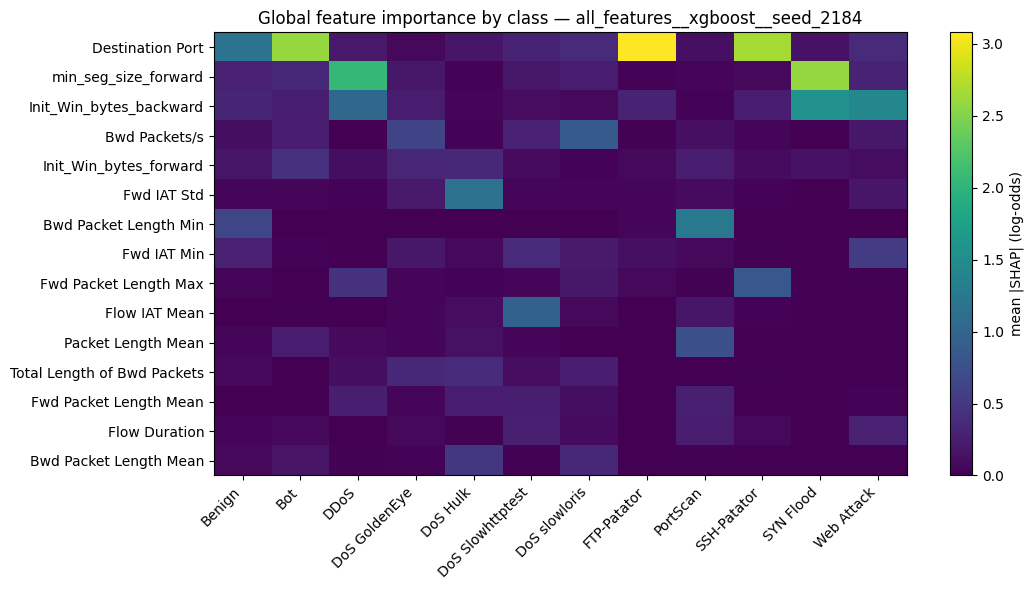

In [11]:
top = b.groupby("feature")["mean_abs_shap_all_rows"].sum().nlargest(15).index
heat = (b[b.feature.isin(top)].pivot(index="feature", columns="explained_class",
        values="mean_abs_shap_all_rows").loc[top][inp.class_order])
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(heat.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns, rotation=45, ha="right")
ax.set_yticks(range(len(heat.index))); ax.set_yticklabels(heat.index)
fig.colorbar(im, label="mean |SHAP| (log-odds)"); ax.set_title(f"Global feature importance by class — {best_id}")
plt.tight_layout(); plt.show()

### 8b. Direction: which features push **toward** or **away from** a class?
Bars to the right push the model toward the class; bars to the left push it away. Computed on rows whose true class is the explained class.

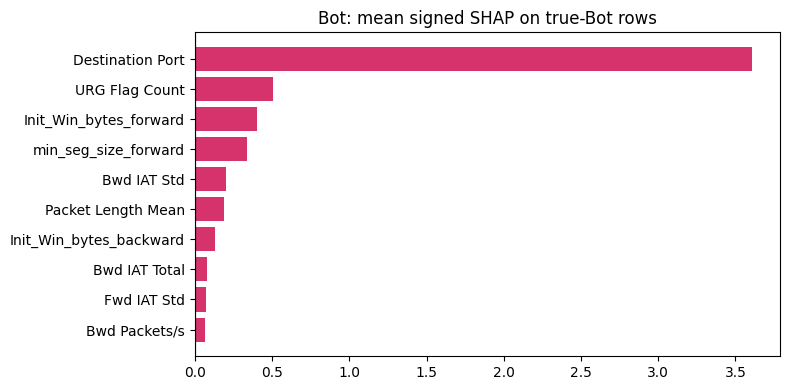

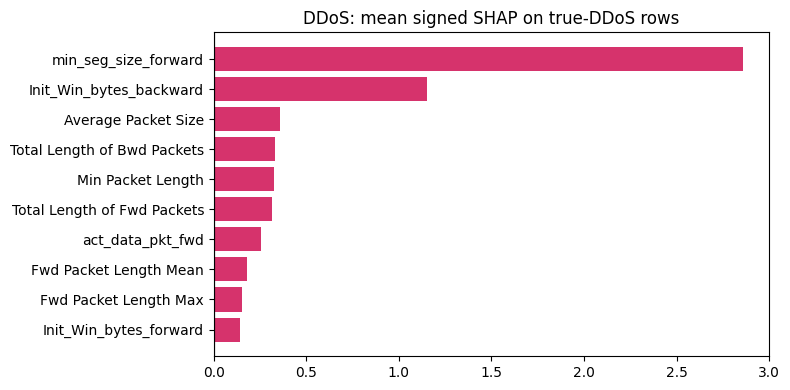

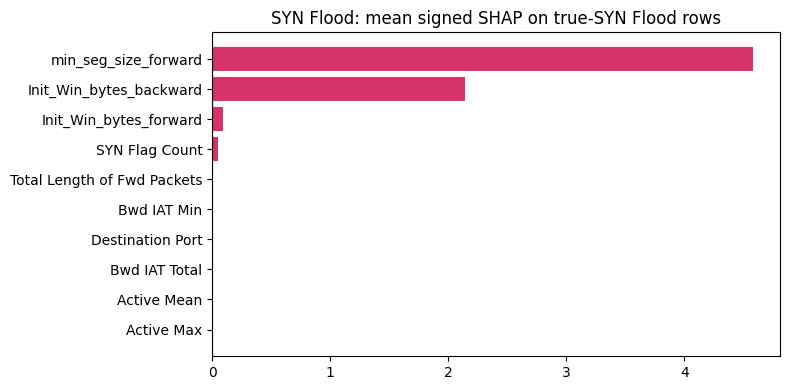

In [12]:
def direction_plot(cls):
    d = b[b.explained_class == cls].copy()
    d = d.reindex(d.mean_signed_shap_true_class_rows.abs().sort_values(ascending=False).index).head(10).iloc[::-1]
    colors = np.where(d.mean_signed_shap_true_class_rows > 0, "#d6336c", "#1c7ed6")
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(d.feature, d.mean_signed_shap_true_class_rows, color=colors)
    ax.axvline(0, color="black", lw=0.8); ax.set_title(f"{cls}: mean signed SHAP on true-{cls} rows")
    plt.tight_layout(); plt.show()
for c in ["Bot", "DDoS", "SYN Flood"]:
    direction_plot(c)

### 8c. The Bot false-positive behaviour of the best run
Benign rows that the model predicted as Bot (in the 1,200-row sample):

In [13]:
pb = pred[pred.experiment_id == best_id]
display(pd.crosstab(pb.true_label, pb.predicted_label).reindex(index=inp.class_order, columns=inp.class_order, fill_value=0))

predicted_label,Benign,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,PortScan,SSH-Patator,SYN Flood,Web Attack
true_label,,,,,,,,,,,,
Benign,100,0,0,0,0,0,0,0,0,0,0,0
Bot,0,100,0,0,0,0,0,0,0,0,0,0
DDoS,0,0,100,0,0,0,0,0,0,0,0,0
DoS GoldenEye,0,0,0,100,0,0,0,0,0,0,0,0
DoS Hulk,0,0,0,0,100,0,0,0,0,0,0,0
DoS Slowhttptest,1,0,0,0,0,97,2,0,0,0,0,0
DoS slowloris,0,0,0,0,0,1,98,0,0,0,0,1
FTP-Patator,0,0,0,0,0,0,0,100,0,0,0,0
PortScan,0,0,0,0,0,0,0,0,100,0,0,0


## 9. Local explanations for the best model (correct predictions and errors)

**correct_benign__s60__explain-benign**

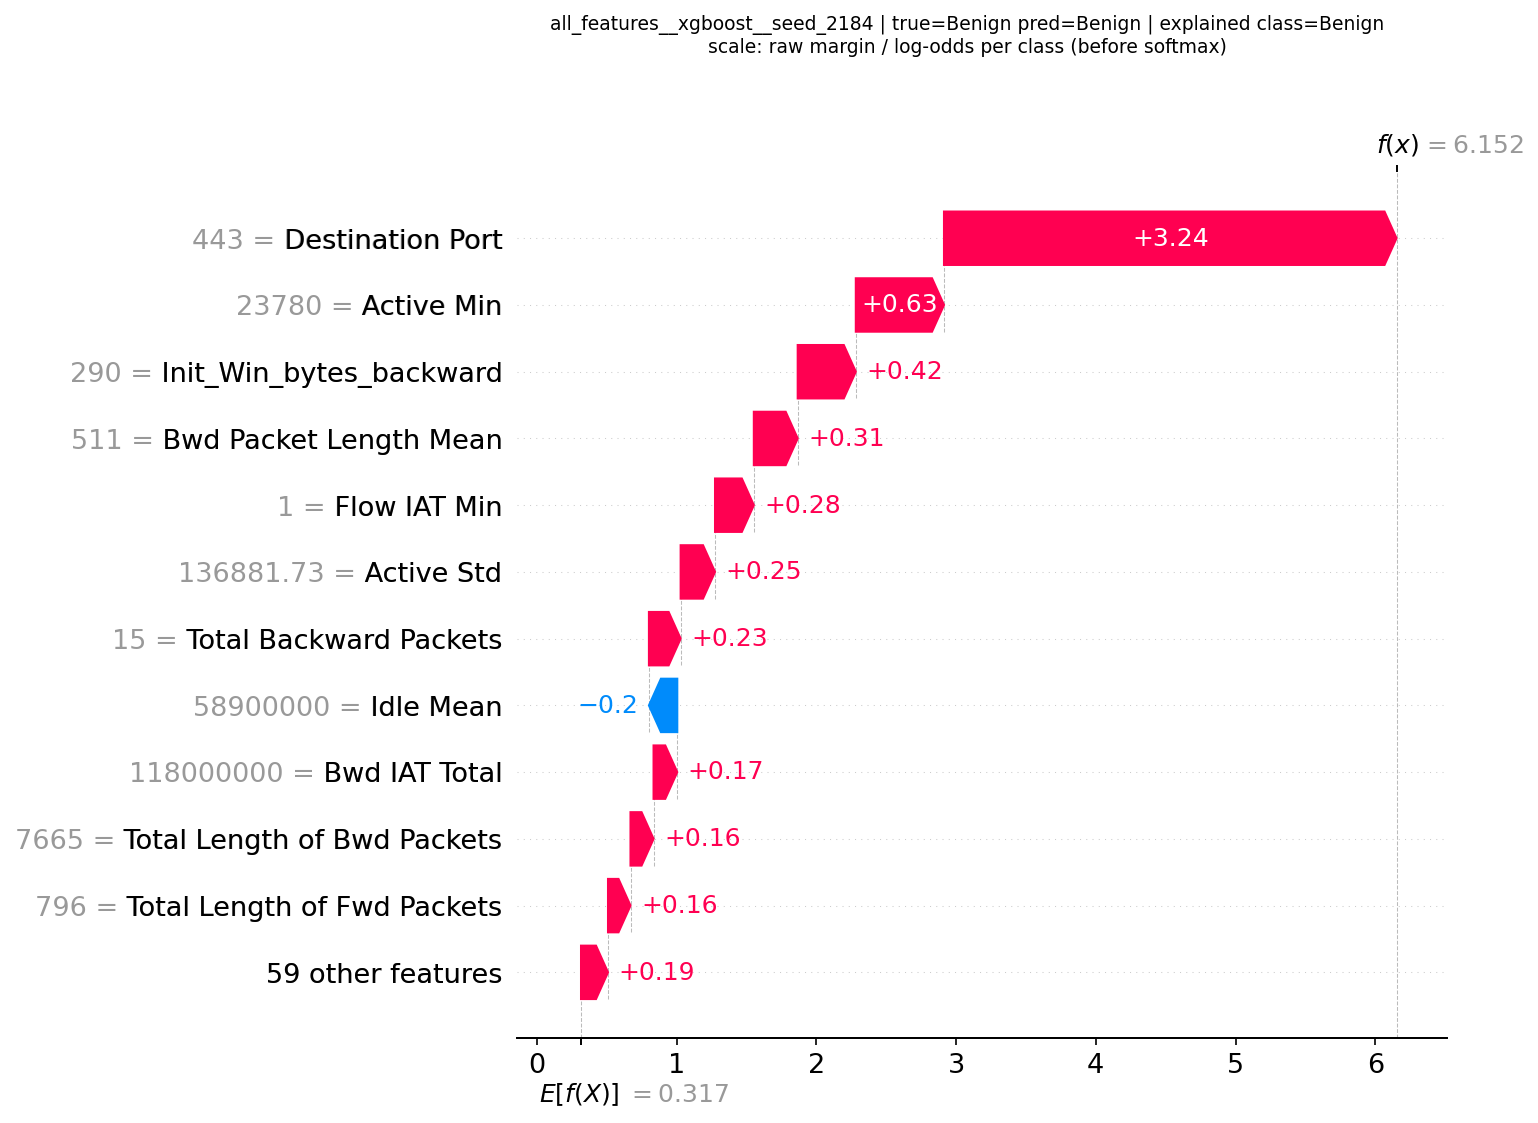

**correct_bot__s180__explain-bot**

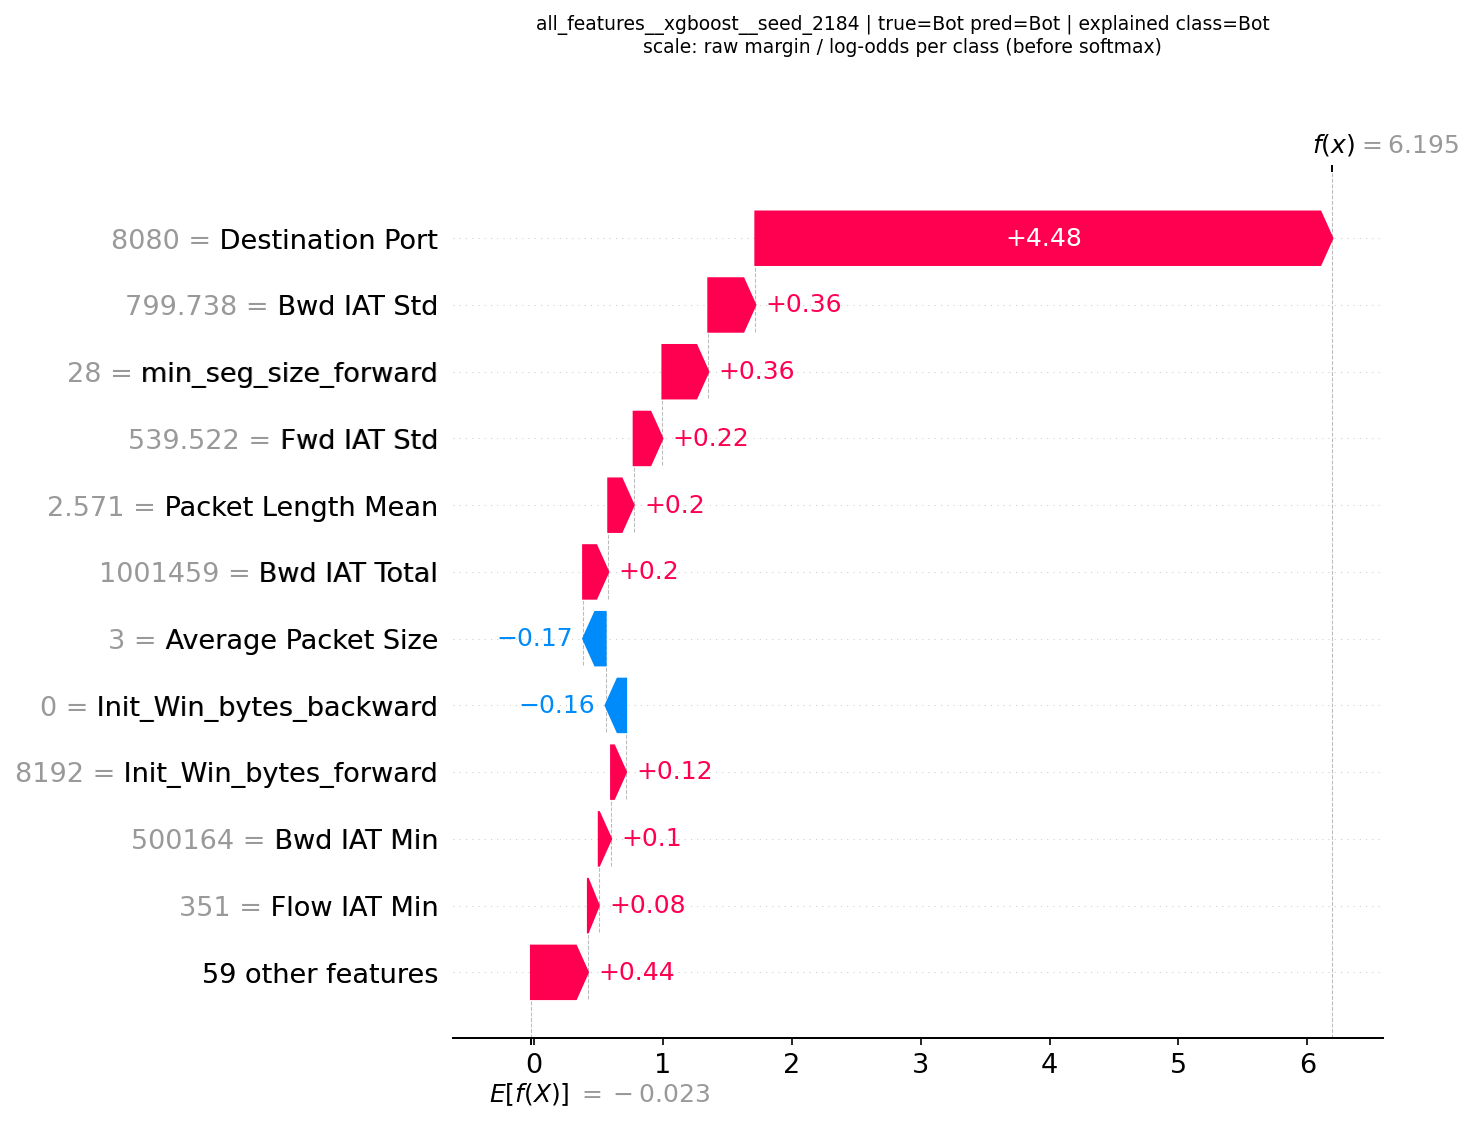

**correct_ddos__s297__explain-ddos**

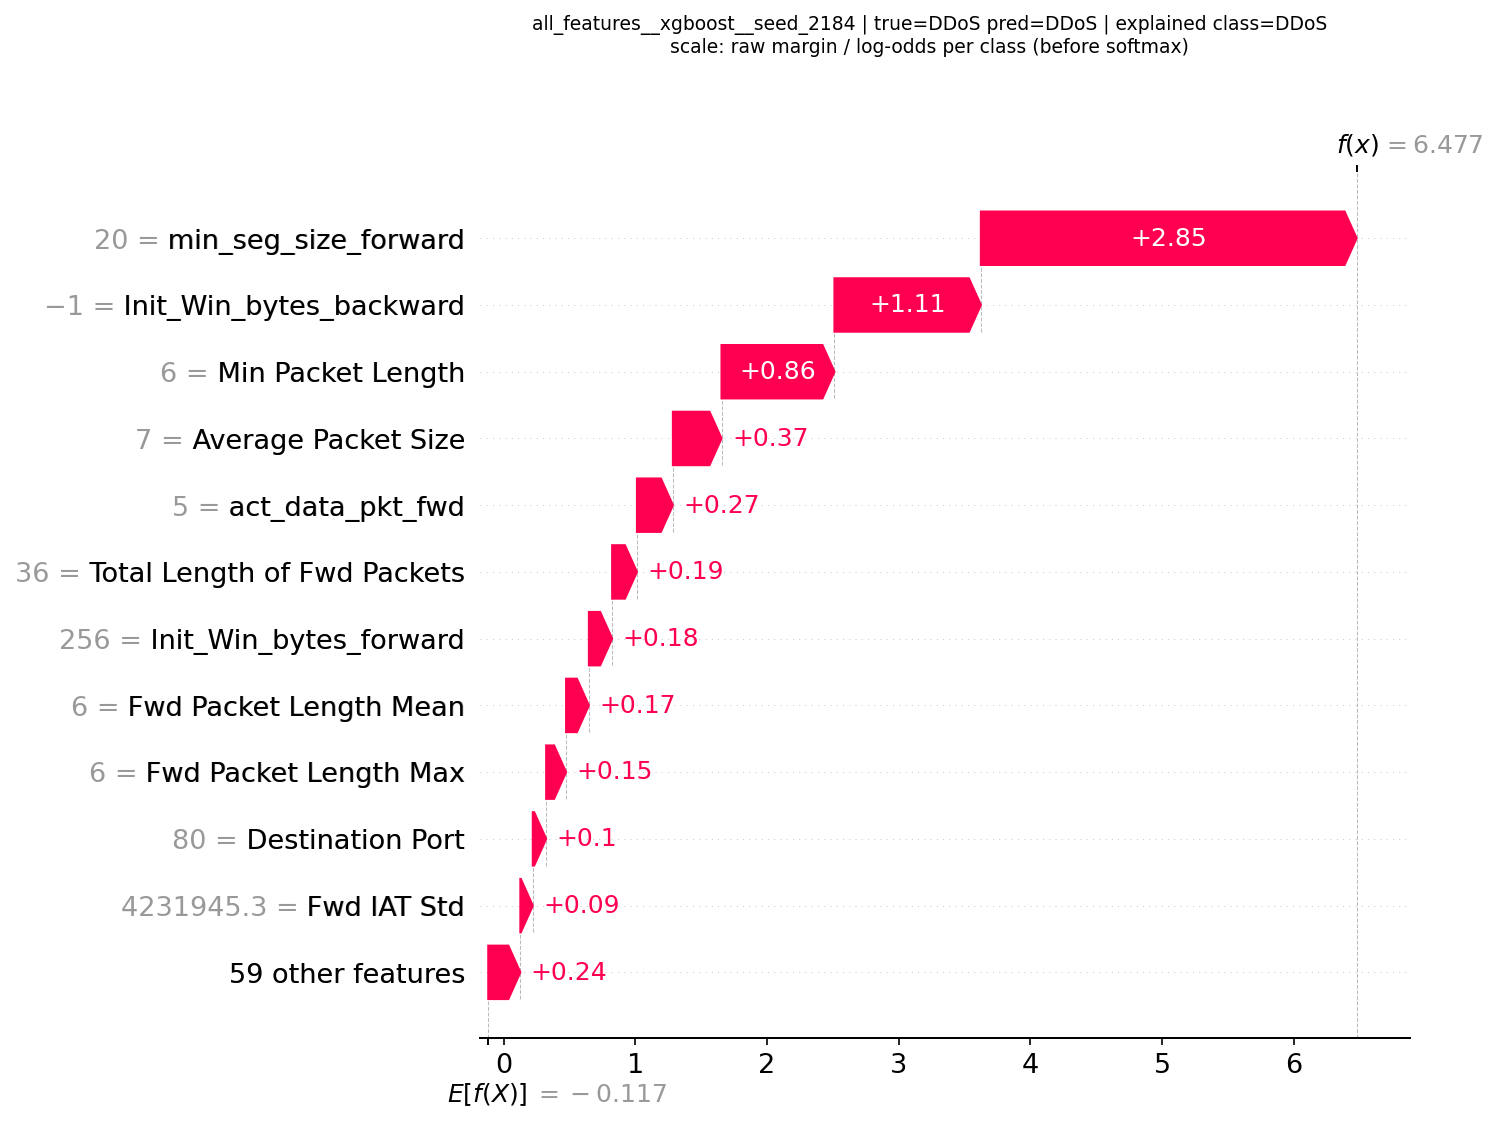

**error_most_confident__s575__explain-dos-slowhttptest**

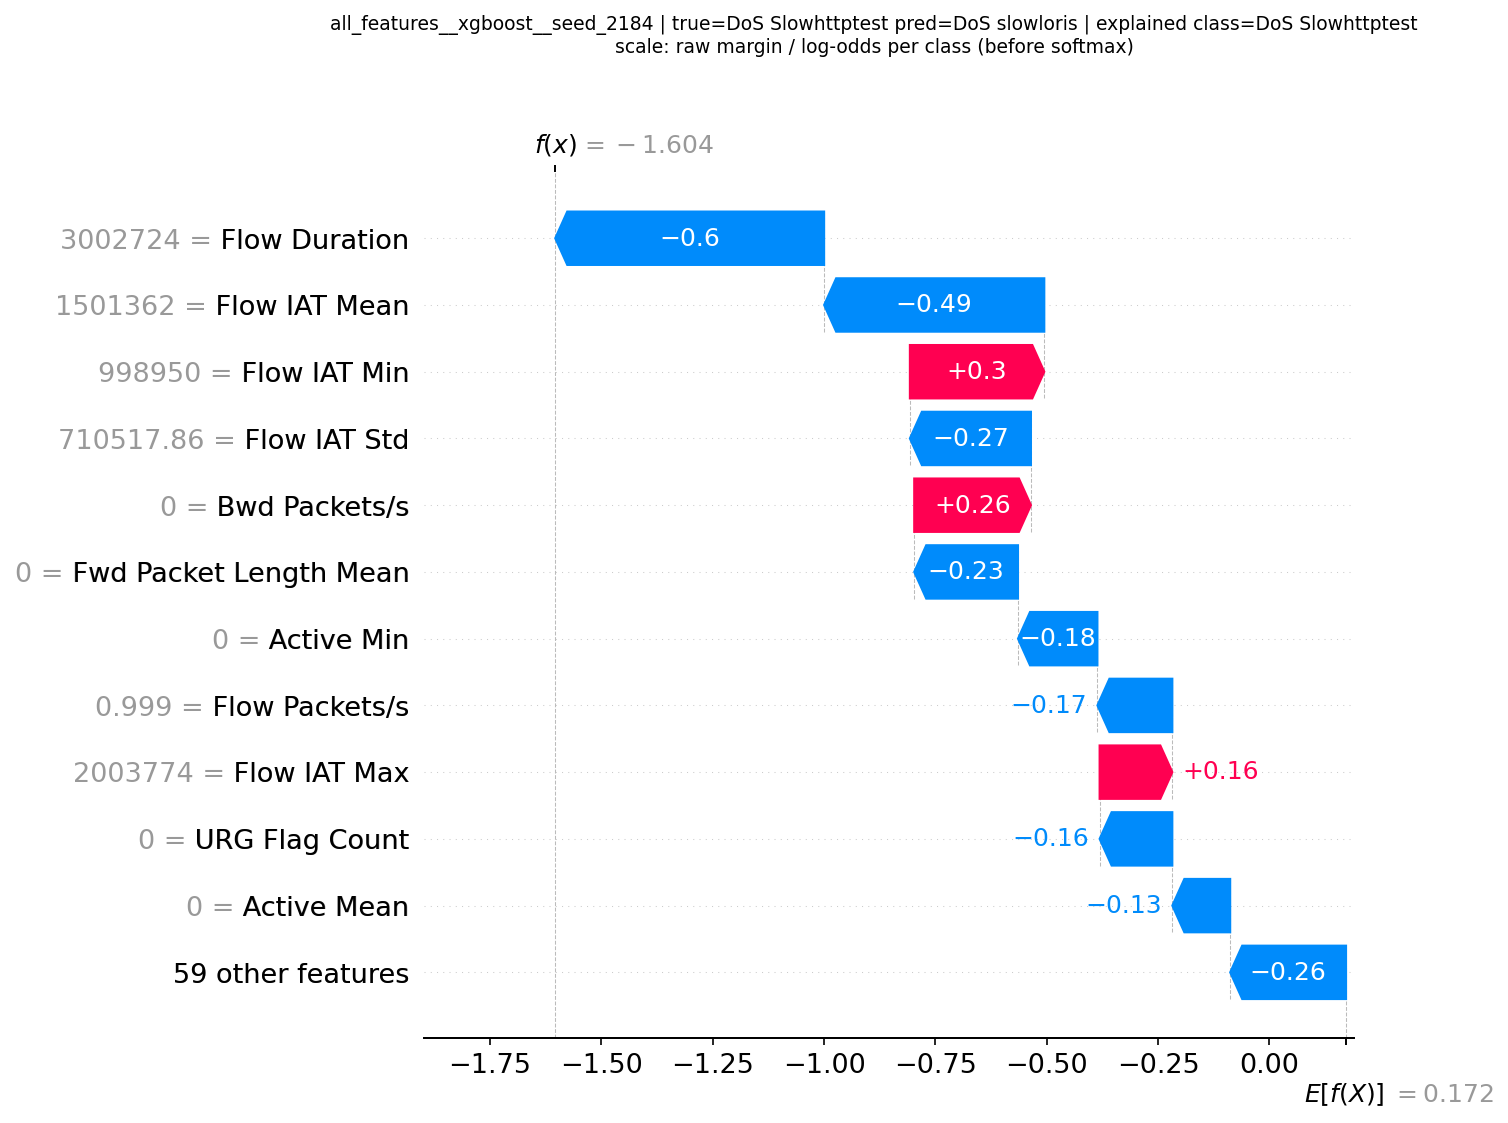

**error_most_confident__s575__explain-dos-slowloris**

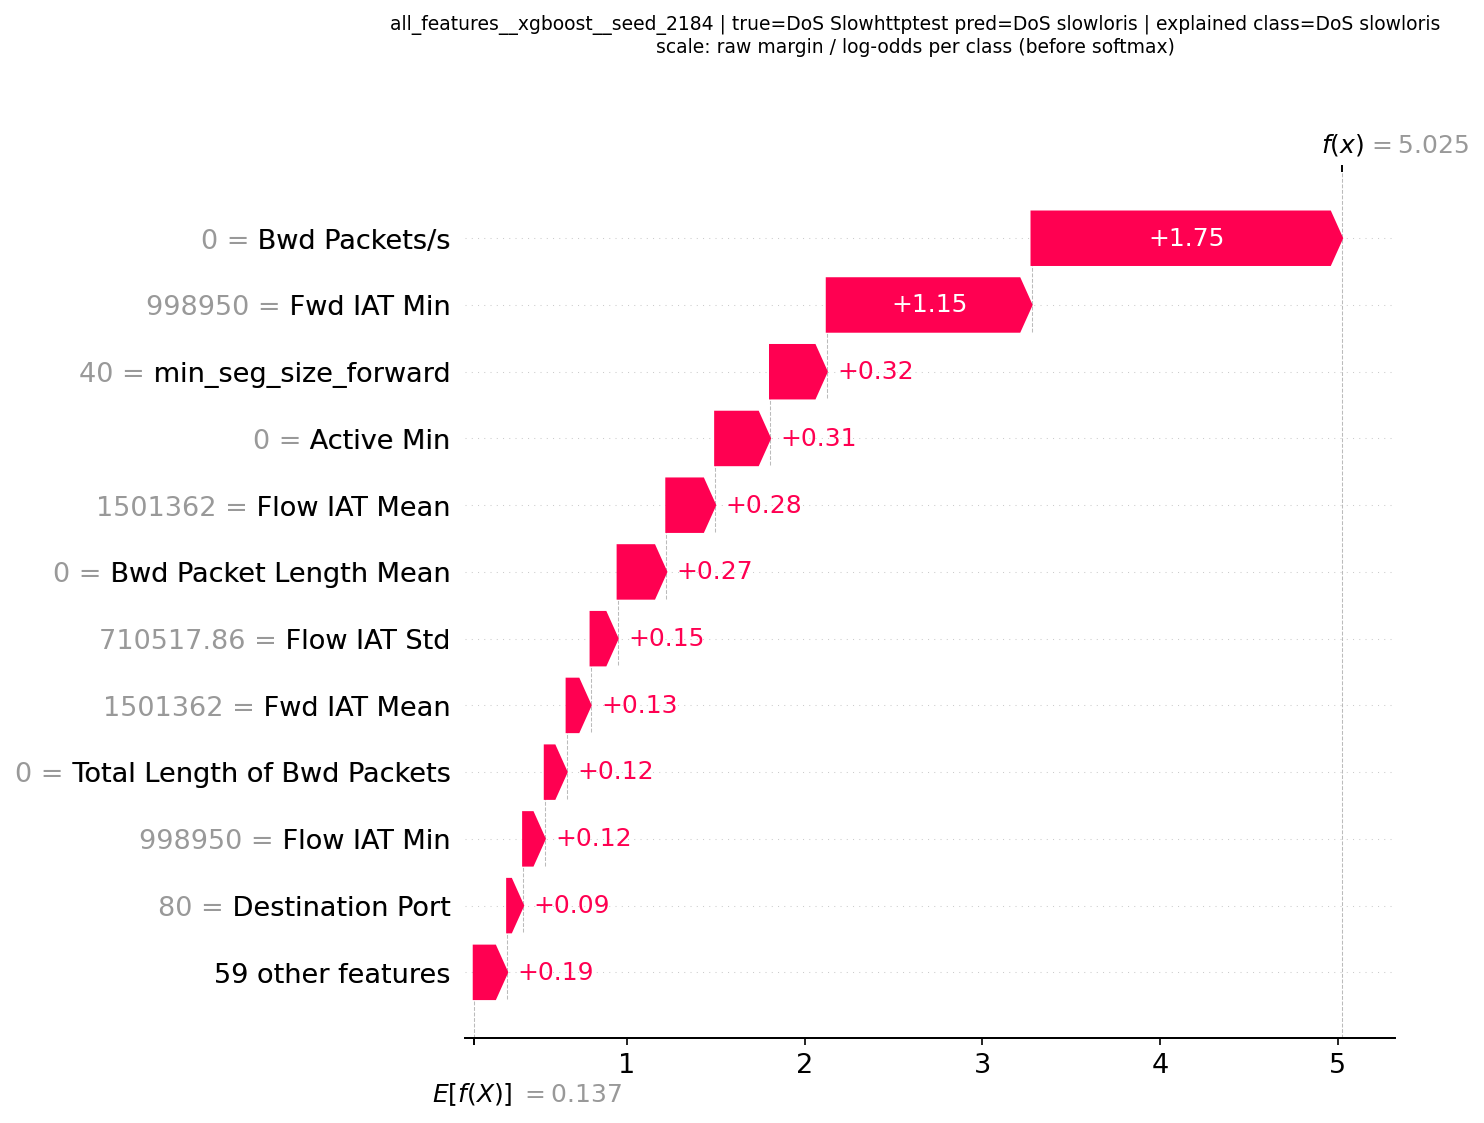

In [14]:
for png in sorted((inp.paths.local_dir / sa._slug(best_id)).glob("*.png")):
    display(Markdown(f"**{png.stem}**"))
    display(Image(filename=str(png), width=620))

## 10. Acceptance checklist (from HANDOFF.md)

In [15]:
res = sa.acceptance_check(inp)
display(pd.Series({k: ("PASS" if v else "FAIL") for k, v in res.items()}, name="result").to_frame())
assert all(res.values()), "Some acceptance checks failed"
print("ALL CHECKS PASSED")

,result
all 200 configurations accounted for,PASS
"same 1,200 test rows used for every configuration",PASS
100 rows from each of the 12 classes,PASS
SHAP additivity passed for every configuration,PASS
every configuration x class x feature row exported,PASS
global importance + direction columns exported,PASS
explainer type and output scale recorded,PASS
local plots exist (correct predictions and errors),PASS
model artifacts unchanged since they were explained,PASS
manifest and README written,PASS


ALL CHECKS PASSED


## Output files (for Tableau / Power BI)
All in `exports/phase06_shap/`: `shap_class_feature_summary.csv` (main chart file), `shap_configuration_summary.csv`,
`shap_sample_predictions.csv`, `shap_sample_features.csv`, `shap_local_cases.csv`, `local_explanations/`, `shap_manifest.json`, `README.txt`.